# Part 3 (simple version) — Know your users before grouping them
Same goal as the advanced notebook, but with the easiest tools: averages, histograms, a correlation table and a 2D picture.

**Idea in one line:** turn each user's many months into **one row per user** (a "profile"), look at how each feature behaves, remove repeated features, and check if users look like they form groups.

*Data note:* this file has no age, gender, account level, or payday/weekend/night info, so those parts of the assignment can't be done here. We use simple substitutes and say so.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/g5_dataSample_v2_processed.csv", parse_dates=["mes"])
print(df.shape[0], "rows (user-months),", df.userId.nunique(), "users")

921438 rows (user-months), 50000 users


## 1. One row per user
We average each user's months. For ratios we only use months where the user actually made purchases (`tx_count_m > 0`), because a ratio with no purchases means nothing.

In [2]:
active = df[df.tx_count_m > 0]          # months with purchases
by_user = active.groupby("userId")
all_months = df.groupby("userId")

F = pd.DataFrame({
    # 1. OXXO dependency
    "oxxo_share":        by_user.oxxo_tx_ratio_m.mean(),
    # 2. Merchant diversity (entropy = how spread out purchases are across merchants)
    "merchant_entropy":  by_user.merchant_entropy_m.mean(),
    # 3. Channel and card mix
    "ecommerce_share":   by_user.ecommerce_tx_ratio_m.mean(),
    "virtual_card_share":by_user.virtual_card_ratio_m.mean(),
    "intl_share":        by_user.intl_tx_ratio_m.mean(),
    # 4. Habits over time (substitutes)
    "active_months_share": all_months.tx_count_m.apply(lambda s: (s > 0).mean()),   # how many months they buy
    "tx_variability":    all_months.tx_count_m.apply(lambda s: s.std() / s.mean() if s.mean() > 0 else np.nan),  # irregular = high
    # 5. Friction (declined payments)
    "decline_rate":      by_user.decline_ratio_m.mean(),
    "months_with_decline": all_months.had_decline_m.mean(),
    # extra: size of activity and funding
    "avg_ticket":        by_user.tx_amount_avg_m.mean(),
    "monthly_spend":     all_months.tx_amount_sum_m.mean(),
    "cash_funding_share":df[~df.is_zero_funding_m].groupby("userId").cash_funding_ratio_m.mean(),
})
F = F.fillna(F.median())   # a few users have no value; fill with the typical value
F.head()

,oxxo_share,merchant_entropy,ecommerce_share,virtual_card_share,intl_share,active_months_share,tx_variability,decline_rate,months_with_decline,avg_ticket,monthly_spend,cash_funding_share
userId,,,,,,,,,,,,
SG5_000131a74409,0.481944,1.184773,0.000000,0.000000,0.000000,1.000000,0.503716,0.140972,0.500000,77.502104,501.187500,0.902236
SG5_0003b71a5ba9,0.042206,1.233388,0.449297,0.000000,0.142229,1.000000,0.654097,0.411603,0.842105,186.133878,1042.160000,0.952526
SG5_0003d78a5121,0.114341,1.131442,0.602661,0.000000,0.000000,1.000000,1.075415,0.039132,0.416667,306.098021,2113.634167,0.981253
SG5_0003df2c9f4e,0.309858,1.625902,0.057204,0.057204,0.002024,1.000000,0.756658,0.240616,0.684211,157.437083,1966.561579,0.731218
SG5_0005332ecd4e,0.097757,1.492589,0.517579,0.489376,0.000000,0.736842,1.214321,0.097024,0.368421,439.515144,1548.156316,0.904840


## 2. Describe every feature
For each one: mean, median, spread (std), percentiles, **skewness** (0 = symmetric, big positive = long tail to the right), **kurtosis** (big = extreme values) and **% zeros**.

In [3]:
rows = []
for f in F.columns:
    x = F[f]
    rows.append({"feature": f, "mean": x.mean(), "median": x.median(), "std": x.std(),
                 "P1": x.quantile(.01), "P25": x.quantile(.25), "P75": x.quantile(.75), "P99": x.quantile(.99),
                 "skew": stats.skew(x), "kurtosis": stats.kurtosis(x), "% zeros": 100 * (x.abs() <= 0.001).mean()})
desc = pd.DataFrame(rows).set_index("feature").round(2)
desc

,mean,median,std,P1,P25,P75,P99,skew,kurtosis,% zeros
feature,,,,,,,,,,
oxxo_share,0.11,0.04,0.16,0.00,0.00,0.14,0.77,2.53,7.71,25.92
merchant_entropy,1.19,1.12,0.62,0.05,0.74,1.59,2.86,0.54,0.09,0.71
ecommerce_share,0.53,0.54,0.36,0.00,0.18,0.91,1.00,-0.09,-1.48,7.94
virtual_card_share,0.14,0.00,0.28,0.00,0.00,0.12,1.00,2.01,2.76,59.46
intl_share,0.14,0.04,0.20,0.00,0.00,0.19,0.88,1.95,3.58,31.16
active_months_share,0.85,0.89,0.14,0.58,0.74,1.00,1.00,-0.49,-1.07,0.00
tx_variability,0.88,0.85,0.33,0.27,0.64,1.08,1.78,0.63,1.15,0.12
decline_rate,0.26,0.20,0.21,0.00,0.08,0.39,0.80,0.82,-0.18,2.30
months_with_decline,0.57,0.58,0.29,0.00,0.33,0.83,1.00,-0.22,-1.06,1.99


**How to read it:** if the mean is much bigger than the median and skew is large (> 1), a few users with huge values are pulling the average — those features need a transformation. Many zeros (e.g. virtual cards) means most people never use it.

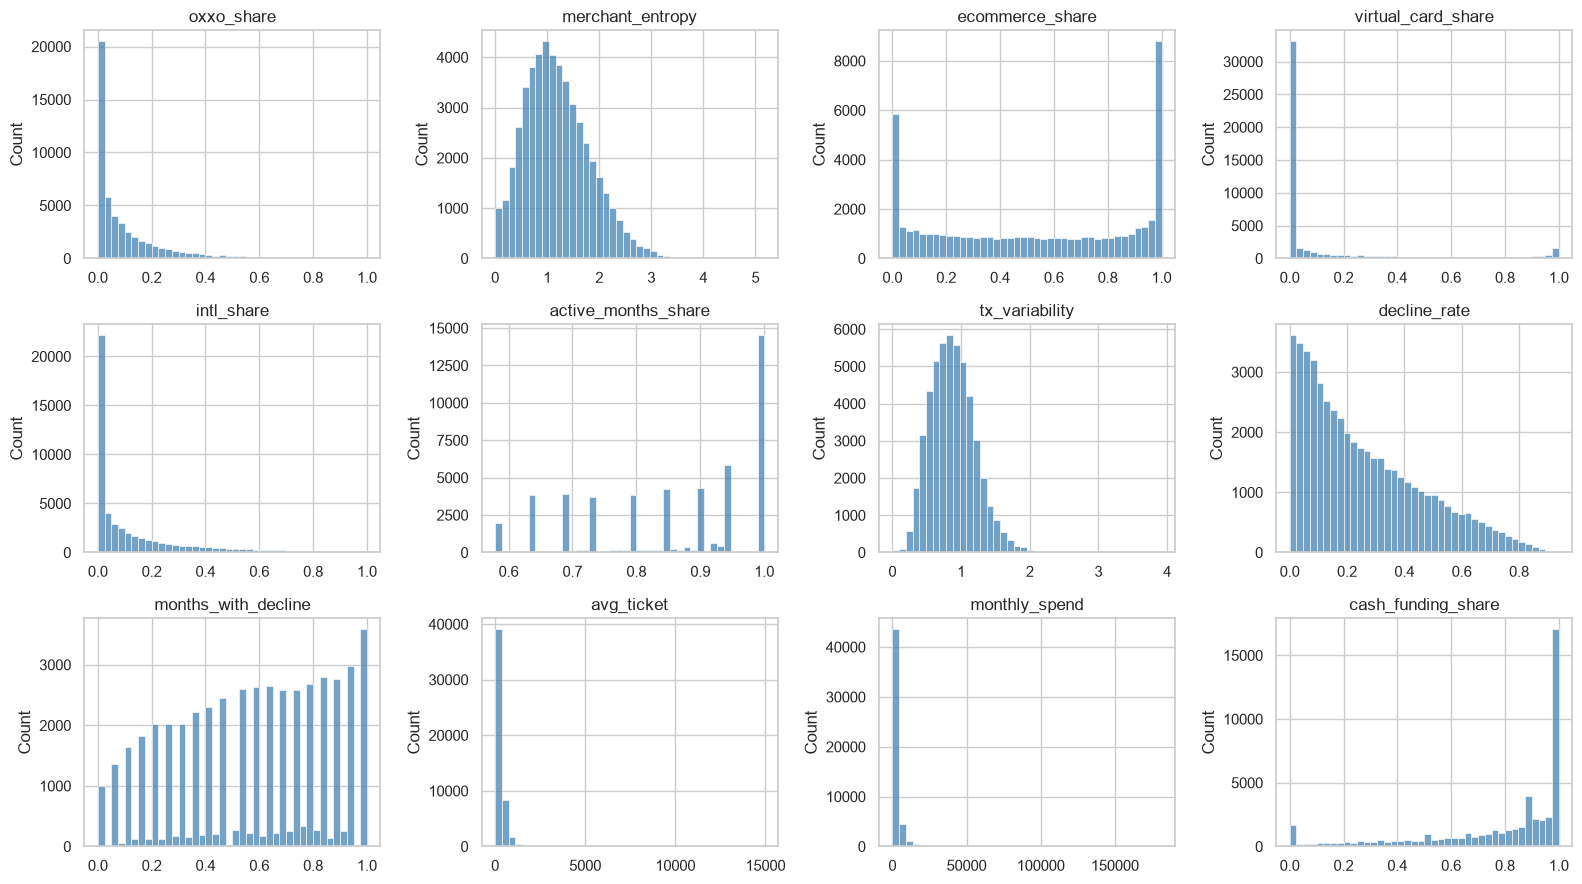

In [4]:
# Histogram of every feature
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, f in zip(axes.flat, F.columns):
    sns.histplot(F[f], bins=40, ax=ax, color="steelblue"); ax.set_title(f); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 3. Fix the very skewed features
Simple recipe: (a) **cap** values above the 99th percentile (winsorize) and (b) take `log(1 + x)` to shrink the long tail. Only for features with skew > 1.

Transformed: ['oxxo_share', 'virtual_card_share', 'intl_share', 'avg_ticket', 'monthly_spend']


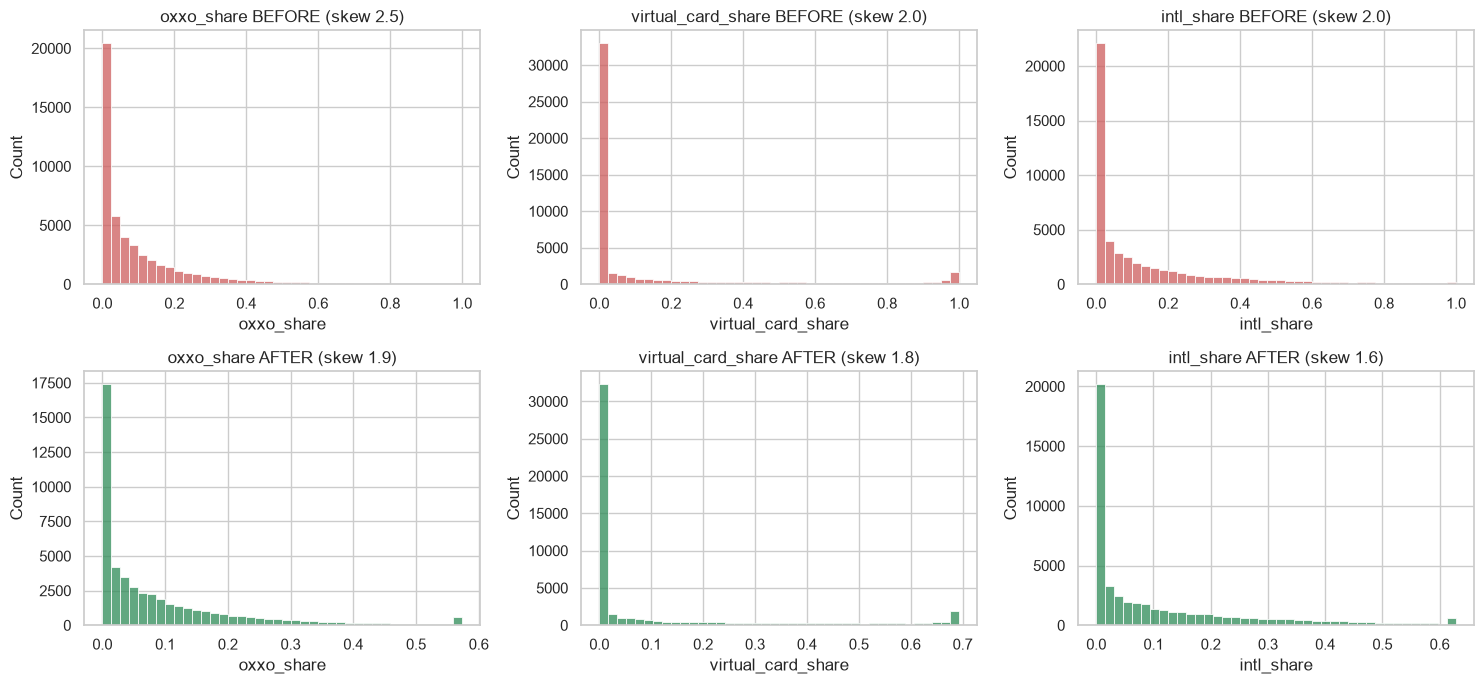

In [5]:
T = F.copy(); changed = []
for f in F.columns:
    if stats.skew(F[f]) > 1:
        T[f] = np.log1p(F[f].clip(upper=F[f].quantile(.99)))
        changed.append(f)
print("Transformed:", changed)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, f in enumerate(changed[:3]):
    sns.histplot(F[f], bins=40, ax=axes[0, i], color="indianred");  axes[0, i].set_title(f"{f} BEFORE (skew {stats.skew(F[f]):.1f})")
    sns.histplot(T[f], bins=40, ax=axes[1, i], color="seagreen");   axes[1, i].set_title(f"{f} AFTER (skew {stats.skew(T[f]):.1f})")
plt.tight_layout(); plt.show()

## 4. Features with no information
A feature where almost everyone has the same value cannot separate users. Rule: drop it if > 95% zeros.

In [6]:
useless = desc[desc["% zeros"] > 95].index.tolist()
print("No-information features:", useless if useless else "none in this table")
print("In the raw data, spend_velocity_index_m was ~83-99% zeros in the other file, so it is not used; the spending-speed idea lives in EDAbd2 (burn ratio).")

No-information features: none in this table
In the raw data, spend_velocity_index_m was ~83-99% zeros in the other file, so it is not used; the spending-speed idea lives in EDAbd2 (burn ratio).


## 5. Repeated information (correlation)
Two features that move together tell the same story. We use **Spearman** correlation (works with skewed data). Close to +1/−1 = repeated.

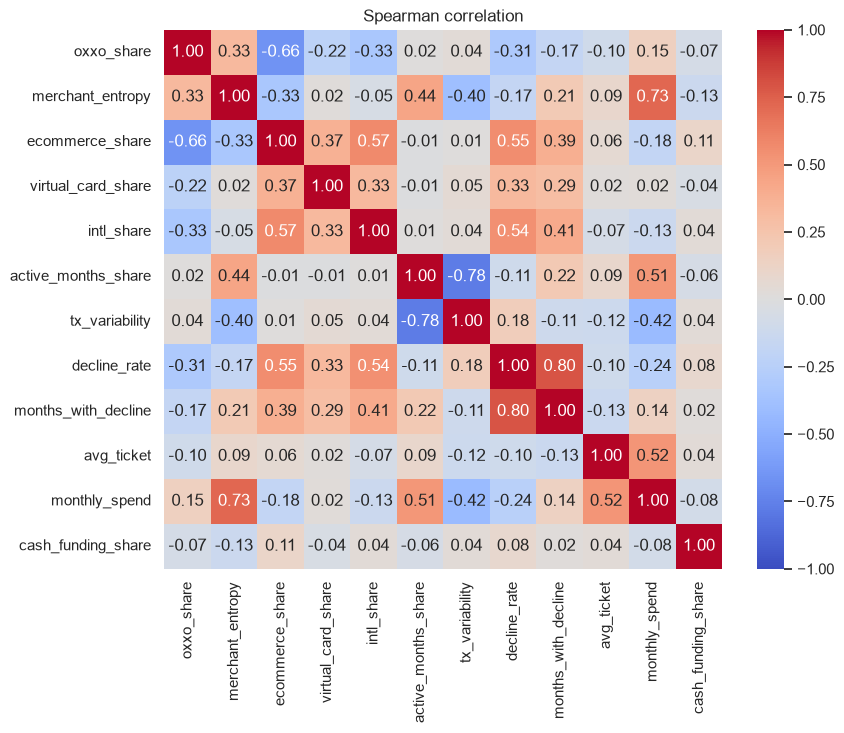

[('merchant_entropy', 'monthly_spend', np.float64(0.73)),
 ('active_months_share', 'tx_variability', np.float64(-0.78)),
 ('decline_rate', 'months_with_decline', np.float64(0.8))]

In [7]:
corr = T.corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation"); plt.show()

# list the pairs that are too similar (|corr| >= 0.7)
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a, b]) >= 0.7]
pairs

In [8]:
# Simple rule: from each too-similar pair, drop the second one
to_drop = set()
for a, b, r in pairs:
    if a not in to_drop and b not in to_drop:
        to_drop.add(b)
keep = [f for f in F.columns if f not in to_drop and f not in useless]
print("Dropped:", sorted(to_drop)); print("Keep:", keep)

Dropped: ['monthly_spend', 'months_with_decline', 'tx_variability']
Keep: ['oxxo_share', 'merchant_entropy', 'ecommerce_share', 'virtual_card_share', 'intl_share', 'active_months_share', 'decline_rate', 'avg_ticket', 'cash_funding_share']


## 6. Feature readiness table

In [9]:
ready = pd.DataFrame({
    "Feature": F.columns,
    "% missing": 0.0,   # missing values were filled in step 1 (only a few users)
    "Skewness": [round(stats.skew(F[f]), 2) for f in F.columns],
    "Transformation": ["cap P99 + log" if f in changed else "none" for f in F.columns],
    "Keep/Drop": ["Keep" if f in keep else "Drop" for f in F.columns],
    "Justification": [("repeats another feature (corr >= 0.7)" if f in to_drop else "no information" if f in useless else "adds its own information") for f in F.columns]})
ready

,Feature,% missing,Skewness,Transformation,Keep/Drop,Justification
0,oxxo_share,0.0,2.53,cap P99 + log,Keep,adds its own information
1,merchant_entropy,0.0,0.54,none,Keep,adds its own information
2,ecommerce_share,0.0,-0.09,none,Keep,adds its own information
3,virtual_card_share,0.0,2.01,cap P99 + log,Keep,adds its own information
4,intl_share,0.0,1.95,cap P99 + log,Keep,adds its own information
5,active_months_share,0.0,-0.49,none,Keep,adds its own information
6,tx_variability,0.0,0.63,none,Drop,repeats another feature (corr >= 0.7)
7,decline_rate,0.0,0.82,none,Keep,adds its own information
8,months_with_decline,0.0,-0.22,none,Drop,repeats another feature (corr >= 0.7)
9,avg_ticket,0.0,7.95,cap P99 + log,Keep,adds its own information


## 7. Do users form natural groups?
Three simple checks.

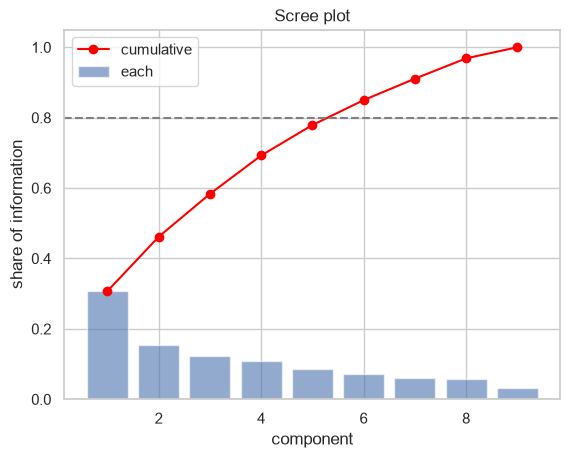

Components needed for 80%: 6


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

Z = StandardScaler().fit_transform(T[keep])     # put all features on the same scale

# (a) PCA "scree": how many combined features do we need to keep most of the information?
pca = PCA().fit(Z); cum = pca.explained_variance_ratio_.cumsum()
plt.bar(range(1, len(cum)+1), pca.explained_variance_ratio_, alpha=.6, label="each")
plt.plot(range(1, len(cum)+1), cum, "o-", color="red", label="cumulative"); plt.axhline(.8, ls="--", color="grey")
plt.xlabel("component"); plt.ylabel("share of information"); plt.legend(); plt.title("Scree plot"); plt.show()
print("Components needed for 80%:", int((cum >= .8).argmax() + 1))

In [11]:
# (b) Hopkins statistic: ~0.5 = no groups (random), close to 1 = clear groups
rng = np.random.default_rng(0)
def hopkins(X, m=1000):
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    real = X[rng.choice(len(X), m, replace=False)]
    d_real = nn.kneighbors(real, 2)[0][:, 1]                          # distance to nearest OTHER real user
    fake = rng.uniform(X.min(0), X.max(0), (m, X.shape[1]))            # random points
    d_fake = nn.kneighbors(fake, 1)[0][:, 0]
    return d_fake.sum() / (d_fake.sum() + d_real.sum())
print("Hopkins:", round(hopkins(Z), 3))

Hopkins: 0.839


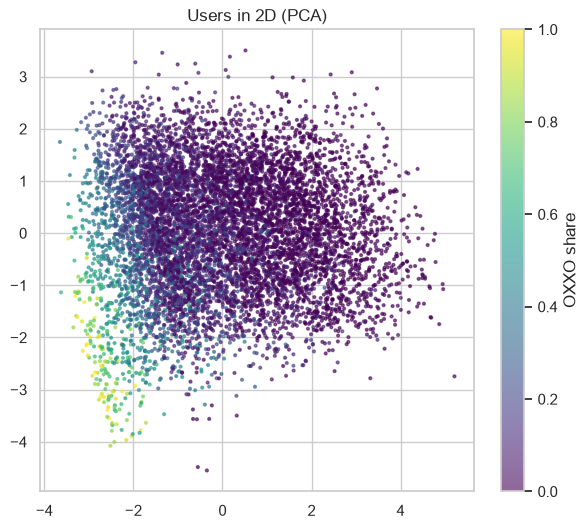

In [12]:
# (c) 2D picture: squash all features into 2 axes (PCA) and colour by OXXO share
P = PCA(2).fit_transform(Z); s = rng.choice(len(Z), 8000, replace=False)
plt.figure(figsize=(7, 6)); sc = plt.scatter(P[s, 0], P[s, 1], c=F.oxxo_share.values[s], s=4, cmap="viridis", alpha=.6)
plt.colorbar(sc, label="OXXO share"); plt.title("Users in 2D (PCA)"); plt.show()

**How to read it:** the scree plot says how many dimensions the behaviour really has; Hopkins above ~0.75 means users are not spread randomly (groups likely); in the 2D picture, look for separate clouds.

## 8. OXXO share

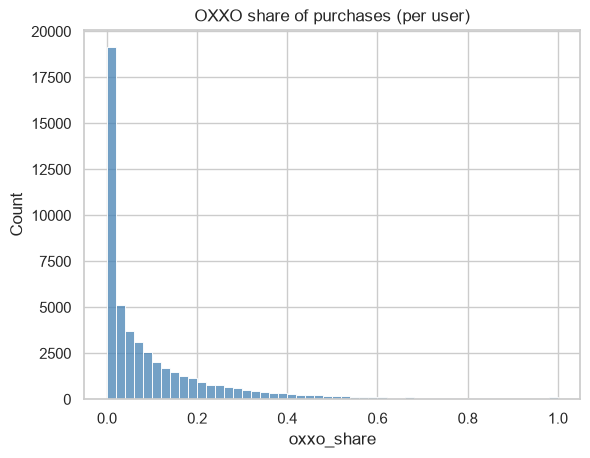

exactly 0: 25.8%   |   <= 1%: 31.7%   |   >= 99%: 0.2%   |   > 50%: 3.7%


In [13]:
o = F.oxxo_share
sns.histplot(o, bins=50, color="steelblue"); plt.title("OXXO share of purchases (per user)"); plt.show()
print(f"exactly 0: {(o==0).mean()*100:.1f}%   |   <= 1%: {(o<=.01).mean()*100:.1f}%   |   >= 99%: {(o>=.99).mean()*100:.1f}%   |   > 50%: {(o>.5).mean()*100:.1f}%")

**Read:** a big pile at 0 (many users never use OXXO), a tail to the right, almost nobody at 1. It is not two separate humps; it is 'zero for many, a little for most, a lot for a few'.

## 9. Compare groups of users
No account level / age / gender here, so we split users into **low / mid / high spenders** (thirds of monthly spend) and compare.

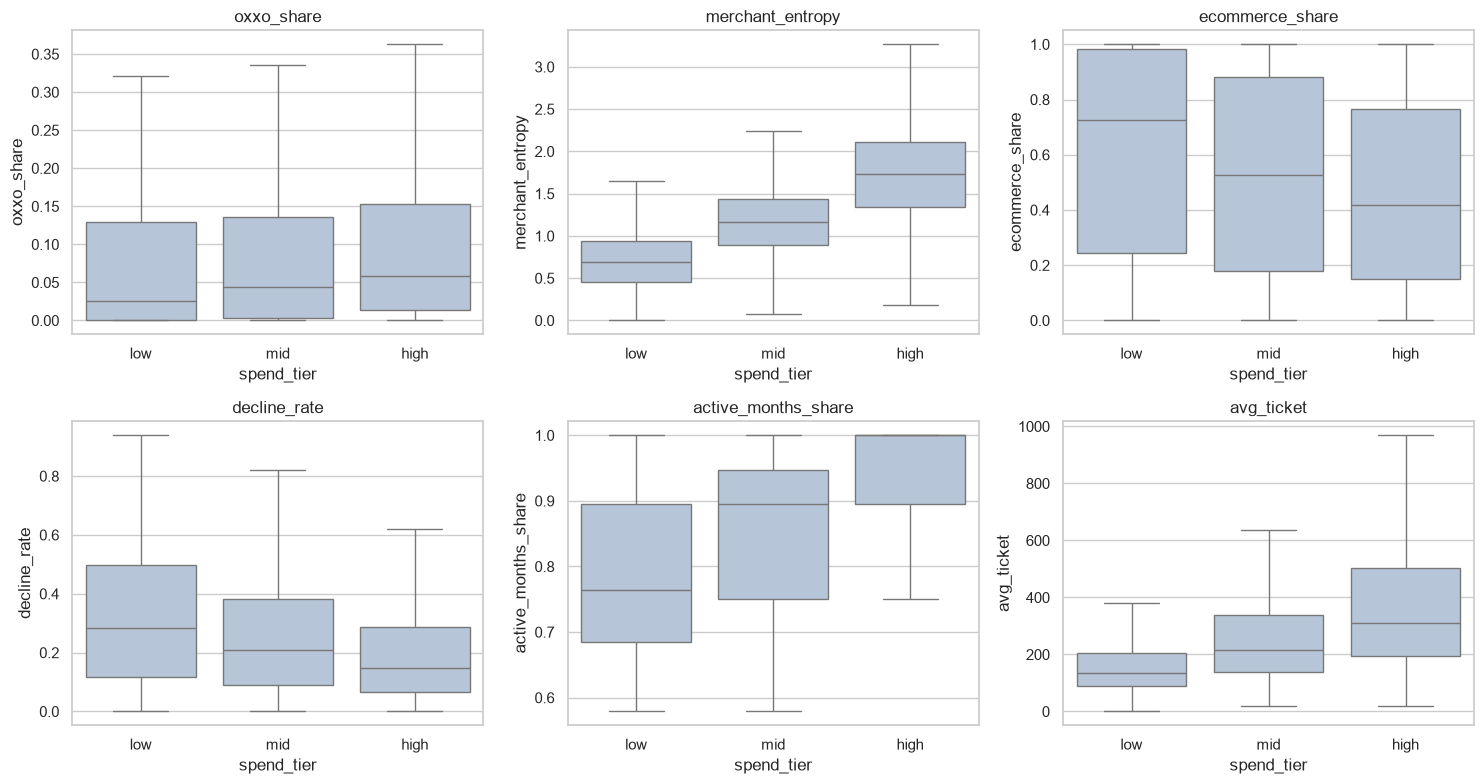

,oxxo_share,merchant_entropy,ecommerce_share,decline_rate
spend_tier,,,,
low,0.026,0.696,0.726,0.285
mid,0.044,1.164,0.528,0.210
high,0.059,1.729,0.419,0.149


In [14]:
F["spend_tier"] = pd.qcut(F.monthly_spend, 3, labels=["low", "mid", "high"])
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.flat, ["oxxo_share", "merchant_entropy", "ecommerce_share", "decline_rate", "active_months_share", "avg_ticket"]):
    sns.boxplot(data=F, x="spend_tier", y=f, ax=ax, showfliers=False, color="lightsteelblue"); ax.set_title(f)
plt.tight_layout(); plt.show()
F.groupby("spend_tier", observed=True)[["oxxo_share", "merchant_entropy", "ecommerce_share", "decline_rate"]].median().round(3)

**Should things like age or account level be used to make the groups?** No. Build groups from *behaviour* only; afterwards, check who is in each group (age, level, etc.). Otherwise the groups just repeat the demographics.

## 10. Would the groups last over time?
Simple check: split the months into the first half and the second half, rebuild a few features, and compare.

In [15]:
mid = df.mes.min() + (df.mes.max() - df.mes.min()) / 2
def quick(d):
    a = d[d.tx_count_m > 0].groupby("userId")
    return pd.DataFrame({"oxxo_share": a.oxxo_tx_ratio_m.mean(), "ecommerce_share": a.ecommerce_tx_ratio_m.mean(),
                         "merchant_entropy": a.merchant_entropy_m.mean(), "decline_rate": a.decline_ratio_m.mean()})
A, B = quick(df[df.mes <= mid]), quick(df[df.mes > mid])
both = A.join(B, lsuffix="_1st", rsuffix="_2nd", how="inner").dropna()
out = pd.DataFrame({"median 1st half": A.median(), "median 2nd half": B.median(),
                    "same user, 1st vs 2nd (corr)": [both[f"{c}_1st"].corr(both[f"{c}_2nd"], method="spearman") for c in A.columns]}).round(2)
out

,median 1st half,median 2nd half,"same user, 1st vs 2nd (corr)"
oxxo_share,0.04,0.03,0.69
ecommerce_share,0.50,0.58,0.84
merchant_entropy,1.07,1.13,0.64
decline_rate,0.17,0.22,0.66


**Read:** medians almost equal = the population looks the same over time. A high correlation (close to 1) = each user behaves similarly in both halves, so groups based on that feature should last. Low = that behaviour changes a lot.

## Summary
Fill in with your own words after reading the outputs: which features were dropped and why, whether Hopkins/scree suggest groups, what the OXXO histogram shows, and which features stay stable over time.